# Лабораторная работа №1. Инструментальные средства машинного обучения
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович **Группа:** ИНС-м-о-25-2  

**Цель:** изучить программные средства организации рабочего места специалиста по анализу данных и машинному обучению; освоить воспроизводимый первичный анализ данных.

**Задачи:** настроить среду Python и Jupyter; изучить загрузку, типы, очистку и предварительную обработку данных; освоить NumPy, pandas и Matplotlib на учебном примере Iris; выполнить индивидуальный анализ одного сценария RCAEval, рассчитать статистики и построить проекции.


## 1. Локальный запуск проекта
Используются VS Code с расширениями Python и Jupyter и изолированное Conda-окружение Python 3.11. VS Code объединяет редактирование, выбор ядра и просмотр результатов; Conda фиксирует совместимые зависимости. Такой выбор обеспечивает локальное воспроизведение без облачной среды.

Создание окружения из корня проекта:
```bash
conda env create -f environment.yml
conda activate rcaeval-ai
```
В VS Code: **Select Kernel → Python Environments → rcaeval-ai**, затем **Run All**. Уже созданное локальное окружение доступно через `.conda/rcaeval-ai/bin/python`.


Подключаем библиотеки.

In [80]:
from pathlib import Path
from urllib.request import urlopen
from math import comb
from itertools import combinations
from importlib.metadata import version
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from huggingface_hub import hf_hub_download, HfApi
from IPython.display import display, Markdown

Задаём пути к данным и результатам.

In [81]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Откройте проект из его корня или каталога notebooks.')
RAW = ROOT / 'data/raw/rcaeval'
REPORT = ROOT / 'reports/lab01'
FIGURES = REPORT / 'figures'
for directory in (RAW, REPORT, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)

Выводим и сохраняем версии Python и библиотек.

In [82]:
versions = {'python': platform.python_version()}
versions.update({name: version(name) for name in
                 ['pandas', 'numpy', 'matplotlib', 'seaborn', 'pyarrow', 'huggingface_hub', 'nbformat', 'nbclient']})
display(pd.Series(versions, name='Версия'))
if platform.python_version_tuple()[:2] != ('3', '11'):
    warnings.warn('Для целевого воспроизведения выберите Python 3.11 из environment.yml.')
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

python             3.11.17
pandas               2.3.3
numpy                2.2.6
matplotlib          3.10.9
seaborn             0.13.2
pyarrow             21.0.0
huggingface_hub     0.35.3
nbformat            5.11.1
nbclient            0.10.4
Name: Версия, dtype: object

217

## 2. Учебная задача: ирисы Фишера
Повторяем шаги примера методички: загрузка текстового файла, просмотр подвыборки, сравнение структур NumPy и графические проекции. Используется `numpy.genfromtxt`, как в листингах методички.

[Источник UCI Iris](https://archive.ics.uci.edu/dataset/53/iris). Объект — цветок; четыре количественных непрерывных признака — длина и ширина чашелистика (`sepal`) и лепестка (`petal`), в сантиметрах. Пятое поле — номинальная метка вида.

### 2.1. Загрузка оригинального файла
Файл сохраняется локально; повторный запуск не обращается к сети.

Загружаем датасет Iris, если файла ещё нет на компьютере.

In [83]:
IRIS_DIR = ROOT / 'data/raw/iris'
IRIS_DIR.mkdir(parents=True, exist_ok=True)
iris_path = IRIS_DIR / 'iris.data'
iris_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'

if not iris_path.is_file():
    with urlopen(iris_url, timeout=60) as response:
        iris_path.write_bytes(response.read())

Печатаем первые пять строк файла.

In [84]:
print('Первые строки файла:')
print('\n'.join(iris_path.read_text(encoding='utf-8').splitlines()[:5]))

Первые строки файла:
5.1,3.5,1.4,0.2,Iris-setosa
4.9,3.0,1.4,0.2,Iris-setosa
4.7,3.2,1.3,0.2,Iris-setosa
4.6,3.1,1.5,0.2,Iris-setosa
5.0,3.6,1.4,0.2,Iris-setosa


### 2.2. Числовой массив и причина NaN
По умолчанию `genfromtxt` пытается прочитать все поля как числа. Текст вида не преобразуется в `float`, поэтому пятый столбец становится `NaN`. Это потеря информации при неверно выбранном способе чтения, а не пропуски в исходном Iris.

Читаем Iris как числовой массив.

In [85]:
iris_numeric = np.genfromtxt(iris_path, delimiter=',')

Выводим первые записи, размер массива и количество NaN.

In [86]:
print('Тип:', type(iris_numeric), 'Форма:', iris_numeric.shape, 'dtype:', iris_numeric.dtype)
print(iris_numeric[:10])
print('NaN в каждом столбце:', np.isnan(iris_numeric).sum(axis=0))
assert iris_numeric.shape == (150, 5)
assert np.isnan(iris_numeric[:, 4]).all()
assert np.isfinite(iris_numeric[:, :4]).all()

Тип: <class 'numpy.ndarray'> Форма: (150, 5) dtype: float64
[[5.1 3.5 1.4 0.2 nan]
 [4.9 3.  1.4 0.2 nan]
 [4.7 3.2 1.3 0.2 nan]
 [4.6 3.1 1.5 0.2 nan]
 [5.  3.6 1.4 0.2 nan]
 [5.4 3.9 1.7 0.4 nan]
 [4.6 3.4 1.4 0.3 nan]
 [5.  3.4 1.5 0.2 nan]
 [4.4 2.9 1.4 0.2 nan]
 [4.9 3.1 1.5 0.1 nan]]
NaN в каждом столбце: [  0   0   0   0 150]


### 2.3. Автоматический и явно заданный тип записи
`dtype=None` выводит тип каждого поля: получается одномерный структурированный массив записей, а не двумерная числовая матрица. `encoding='bytes'` воспроизводит байтовые строки из листинга методички. Явный `dtype` задаёт четыре вещественных поля и строку Unicode. В современных версиях поведение кодировки может отличаться, поэтому она задаётся явно.

Массив записей имеет форму `(150,)`, каждая запись — пять разнотипных полей (`numpy.void`); обычный числовой массив выше имеет форму `(150, 5)` и единый dtype. Unicode-строка содержит текст, байтовая строка — его закодированное представление.

Читаем Iris с автоматическим определением типов.

In [87]:
iris_auto = np.genfromtxt(iris_path, delimiter=',', dtype=None, encoding='bytes')

/tmp/ipykernel_2112752/929895966.py:1: VisibleDeprecationWarning: Reading unicode strings without specifying the encoding argument is deprecated. Set the encoding, use None for the system default.
  iris_auto = np.genfromtxt(iris_path, delimiter=',', dtype=None, encoding='bytes')


Читаем Iris с явно заданными типами.

In [88]:
iris_dtype = np.dtype('f8, f8, f8, f8, U30')
iris_explicit = np.genfromtxt(iris_path, delimiter=',', dtype=iris_dtype, encoding='utf-8')

Сравниваем типы и первые записи двух массивов.

In [89]:
for label, array in [('Автоматический тип', iris_auto), ('Явный тип', iris_explicit)]:
    print(label, 'форма:', array.shape, 'dtype:', array.dtype)
    print('Тип массива / записи / метки:', type(array), type(array[0]), type(array[0][4]))
    print(array[:5])
assert np.array_equal(np.char.decode(iris_auto['f4'], 'utf-8'), iris_explicit['f4'])

Автоматический тип форма: (150,) dtype: [('f0', '<f8'), ('f1', '<f8'), ('f2', '<f8'), ('f3', '<f8'), ('f4', 'S15')]
Тип массива / записи / метки: <class 'numpy.ndarray'> <class 'numpy.void'> <class 'numpy.bytes_'>
[(5.1, 3.5, 1.4, 0.2, b'Iris-setosa') (4.9, 3. , 1.4, 0.2, b'Iris-setosa')
 (4.7, 3.2, 1.3, 0.2, b'Iris-setosa') (4.6, 3.1, 1.5, 0.2, b'Iris-setosa')
 (5. , 3.6, 1.4, 0.2, b'Iris-setosa')]
Явный тип форма: (150,) dtype: [('f0', '<f8'), ('f1', '<f8'), ('f2', '<f8'), ('f3', '<f8'), ('f4', '<U30')]
Тип массива / записи / метки: <class 'numpy.ndarray'> <class 'numpy.void'> <class 'numpy.str_'>
[(5.1, 3.5, 1.4, 0.2, 'Iris-setosa') (4.9, 3. , 1.4, 0.2, 'Iris-setosa')
 (4.7, 3.2, 1.3, 0.2, 'Iris-setosa') (4.6, 3.1, 1.5, 0.2, 'Iris-setosa')
 (5. , 3.6, 1.4, 0.2, 'Iris-setosa')]


Создаём таблицу Iris и задаём названия признаков.

In [90]:
iris_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
iris = pd.DataFrame.from_records(iris_explicit)
iris.columns = iris_names
iris_features = iris_names[:4]
iris_labels = {'sepal_length': 'Длина чашелистика, см', 'sepal_width': 'Ширина чашелистика, см',
               'petal_length': 'Длина лепестка, см', 'petal_width': 'Ширина лепестка, см'}

Выводим описание признаков.

In [91]:
display(pd.DataFrame({'Признак': iris_names, 'Смысл': list(iris_labels.values()) + ['Вид ириса'],
                      'Смысловой тип': ['Количественный непрерывный'] * 4 + ['Номинальный, целевая метка'],
                      'Тип хранения': iris.dtypes.astype(str).tolist()}))

,Признак,Смысл,Смысловой тип,Тип хранения
0,sepal_length,"Длина чашелистика, см",Количественный непрерывный,float64
1,sepal_width,"Ширина чашелистика, см",Количественный непрерывный,float64
2,petal_length,"Длина лепестка, см",Количественный непрерывный,float64
3,petal_width,"Ширина лепестка, см",Количественный непрерывный,float64
4,species,Вид ириса,"Номинальный, целевая метка",object


Показываем первые строки таблицы.

In [92]:
display(iris.head())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Считаем объекты каждого вида и пропуски.

In [93]:
display(iris['species'].value_counts().to_frame('Количество'))
display(iris.isna().sum().to_frame('Пропуски'))

,Количество
species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


,Пропуски
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


Рассчитываем статистики и сохраняем их в CSV.

In [94]:
display(iris[iris_features].describe().T)
assert iris['species'].nunique() == 3
assert (iris['species'].value_counts() == 50).all()
assert iris.isna().sum().sum() == 0
# Сохраняем исходные записи: одинаковые измерения разных цветов не обязательно ошибка.
print('Совпадающих строк сверх первой:', int(iris.duplicated().sum()))
iris[iris_features].describe().T.to_csv(REPORT / 'iris_statistics.csv', index_label='Признак')

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.054000,0.433594,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758667,1.764420,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.198667,0.763161,0.1,0.3,1.30,1.8,2.5


Совпадающих строк сверх первой: 3


### 2.4. Проекции данных
Для $p$ признаков число различных пар без перестановки осей: $C_p^2=p(p-1)/2$. Для четырёх измерений получаем шесть проекций. Метка вида служит для цвета и формы маркера, а не пятым измерением. Группируем по фактическим названиям видов, поэтому код не зависит от порядка строк.

Первые три проекции воспроизводят пары с длиной чашелистика из рис. 1.8; остальные дополняют пример всеми возможными парами.

Составляем пары признаков и считаем число проекций.

In [95]:
iris_pairs = list(combinations(iris_features, 2))
print('Всего парных проекций:', comb(len(iris_features), 2))

Всего парных проекций: 6


Строим и сохраняем шесть проекций Iris.

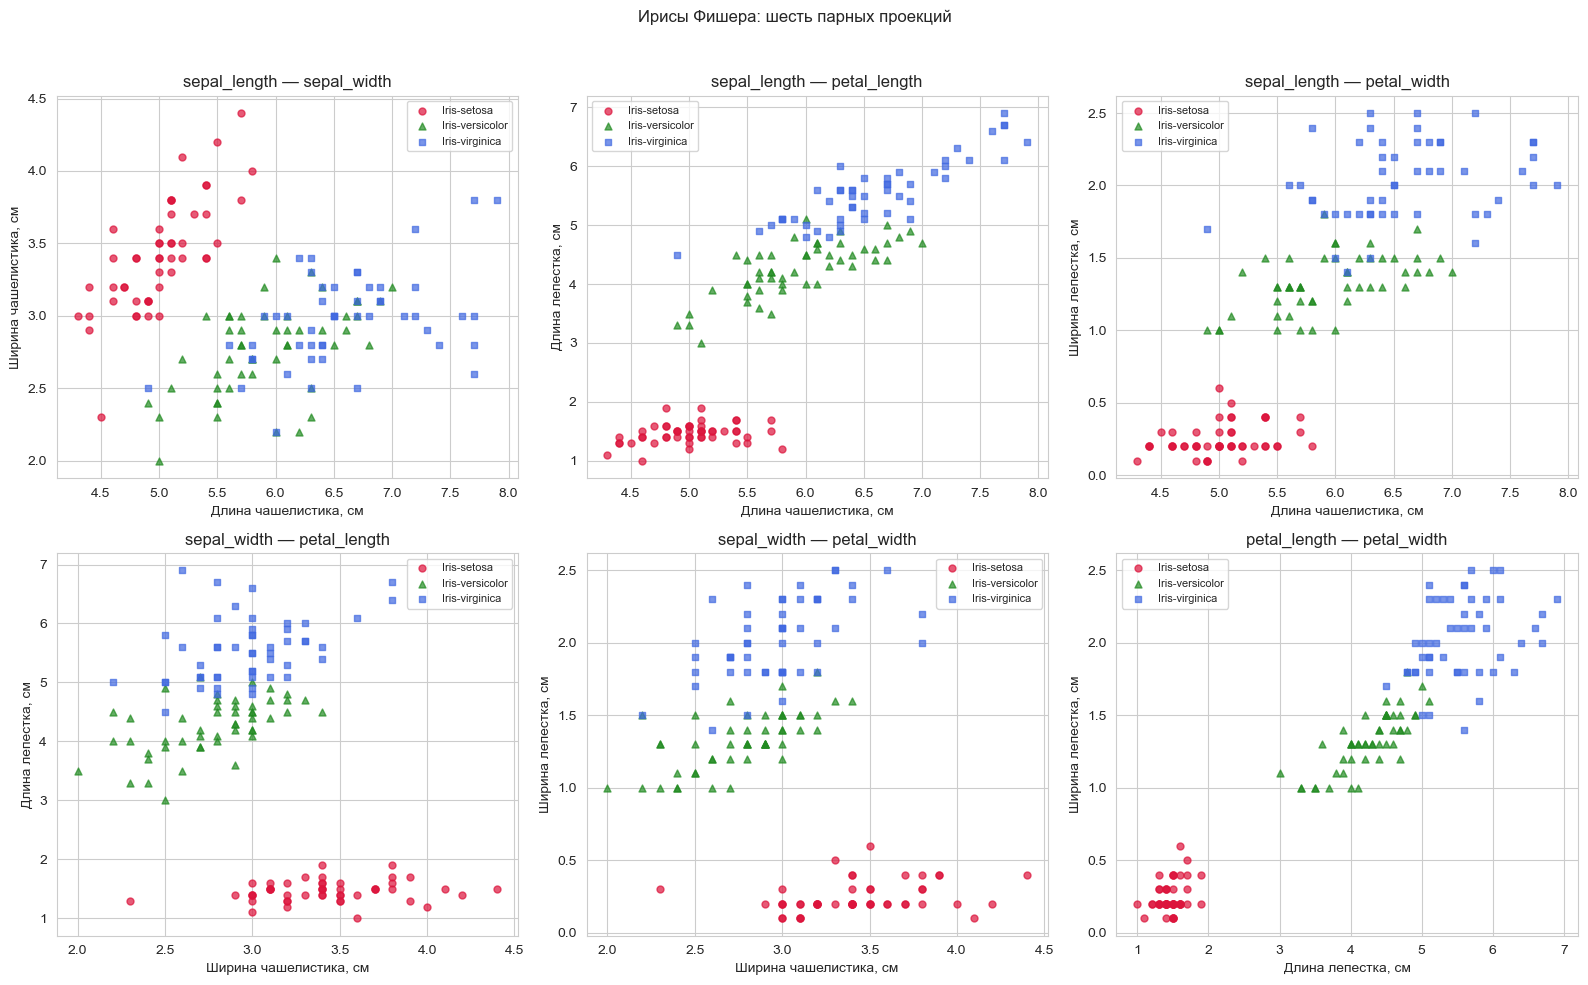

In [96]:
with sns.axes_style('whitegrid'):
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, (x, y) in zip(axes.flat, iris_pairs):
        for species, color, marker in zip(sorted(iris['species'].unique()),
                                           ['crimson', 'forestgreen', 'royalblue'], ['o', '^', 's']):
            group = iris[iris['species'] == species]
            ax.scatter(group[x], group[y], color=color, marker=marker, s=25, alpha=0.7, label=species)
        ax.set(xlabel=iris_labels[x], ylabel=iris_labels[y], title=f'{x} — {y}')
        ax.legend(fontsize=8)
    fig.suptitle('Ирисы Фишера: шесть парных проекций')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(FIGURES / '00_iris_projections.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Сравниваем диапазоны лепестков разных видов и формулируем вывод.

In [97]:
# Диапазоны дают численную опору для интерпретации разделения групп.
display(iris.groupby('species')[['petal_length', 'petal_width']].agg(['min', 'max']))
setosa_max = iris.loc[iris['species'] == 'Iris-setosa', 'petal_length'].max()
others_min = iris.loc[iris['species'] != 'Iris-setosa', 'petal_length'].min()
display(Markdown(f'В этой выборке максимум длины лепестка Setosa равен **{setosa_max:g} см**, '
                 f'минимум остальных видов **{others_min:g} см**. '
                 'На проекциях с лепестками группа Setosa отделяется, а Versicolor и Virginica частично перекрываются. '
                 'Это наблюдение о данной выборке, а не проверенный классификатор для новых растений.'))

petal_length      petal_width     
                         min  max         min  max
species                                           
Iris-setosa              1.0  1.9         0.1  0.6
Iris-versicolor          3.0  5.1         1.0  1.8
Iris-virginica           4.5  6.9         1.4  2.5

В этой выборке максимум длины лепестка Setosa равен **1.9 см**, минимум остальных видов **3 см**. На проекциях с лепестками группа Setosa отделяется, а Versicolor и Virginica частично перекрываются. Это наблюдение о данной выборке, а не проверенный классификатор для новых растений.

## 3. Индивидуальное задание: RCAEval

### 3.1. Описание и выбор набора
RCAEval - это бенчмарк диагностики первопричин сбоев микросервисных систем. RE2 содержит метрики, логи и для поддерживаемых систем трассировки. RE2-OB относится к Online Boutique - демонстрационному интернет-магазину с взаимодействующими микросервисами. Контролируемые сбои и известный сервис-первопричина позволяют сопоставлять телеметрию с инцидентами.

В дальнейшем набор подходит для обнаружения аномалий, классификации неисправностей, прогнозирования нагрузки и диагностики первопричин. Один сценарий недостаточен для оценки обобщающей способности моделей. Сейчас исследуются **только метрики одного сценария**, предпочтительно CPU stress.

Источники: [GitHub RCAEval](https://github.com/phamquiluan/RCAEval), [Hugging Face и описание формата](https://huggingface.co/datasets/phamquiluan/RCAEval). По документации `time` - Unix-секунды, названия метрик имеют вид `{service}_{metric}`. Null обозначает отсутствие измерения на отсчёте; при конвертации заполнение не применялось.

### 3.2. Загрузка данных и выбор сценария
Сначала загружается только индекс. Подходят RE2-OB с метриками и отсчётами по обе стороны внедрения. CPU имеет приоритет, затем применяется сортировка по `case`. Идентификатор и ревизия сохраняются; повторный запуск использует локальные файлы без сетевых запросов. При недоступности данных выполнение останавливается.

Настраиваем загрузку выбранных файлов RCAEval.

In [98]:
REPO = 'phamquiluan/RCAEval'
selection_path = REPORT / 'selected_case.json'
previous = json.loads(selection_path.read_text(encoding='utf-8')) if selection_path.exists() else None
revision = previous['revision'] if previous else HfApi().dataset_info(REPO).sha

def local_file(filename):
    target = RAW / filename
    if not target.is_file():
        hf_hub_download(repo_id=REPO, repo_type='dataset', filename=filename,
                        revision=revision, local_dir=RAW)
    return target


Загружаем индекс сценариев.

In [99]:
cases = pd.read_parquet(local_file('cases.parquet'))
required = {'case', 'dataset', 'fault', 'root_cause_service', 'inject_time',
            'n_metrics', 'n_timesteps', 'normal_timesteps', 'faulty_timesteps'}
if not required.issubset(cases.columns):
    raise ValueError(f'Изменилась схема индекса; отсутствуют: {required - set(cases.columns)}')

Показываем первые записи и сведения об индексе.

In [100]:
print('Сценариев в индексе:', len(cases))
print('Столбцы:', cases.columns.tolist())
display(cases.head())
ob = cases[cases['dataset'] == 'RE2-OB']
print('Сценариев RE2-OB:', len(ob))

Сценариев в индексе: 735
Столбцы: ['case', 'dataset', 'suite', 'system', 'system_name', 'root_cause_service', 'fault', 'fault_description', 'repetition', 'inject_time', 'n_metrics', 'n_timesteps', 'time_start', 'time_end', 'duration_minutes', 'normal_timesteps', 'faulty_timesteps', 'has_logs', 'n_logs', 'has_traces', 'n_traces', 'has_root_cause_file']


,case,dataset,suite,system,system_name,root_cause_service,fault,fault_description,repetition,inject_time,...,time_start,time_end,duration_minutes,normal_timesteps,faulty_timesteps,has_logs,n_logs,has_traces,n_traces,has_root_cause_file
0,re1ob_adservice_cpu_1,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,1,1685202688,...,1685200588,1685204788,70.0,2100,2101,False,0,False,0,False
1,re1ob_adservice_cpu_2,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,2,1685206967,...,1685204867,1685209067,70.0,2100,2101,False,0,False,0,False
2,re1ob_adservice_cpu_3,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,3,1685211245,...,1685209145,1685213345,70.0,2100,2101,False,0,False,0,False
3,re1ob_adservice_cpu_4,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,4,1685229704,...,1685227604,1685231804,70.0,2100,2101,False,0,False,0,False
4,re1ob_adservice_cpu_5,RE1-OB,RE1,ob,Online Boutique,adservice,cpu,CPU stress,5,1685220134,...,1685218034,1685222234,70.0,2100,2101,False,0,False,0,False


Сценариев RE2-OB: 90


Выбираем один подходящий сценарий.

In [101]:
eligible = ob[(ob['n_metrics'] > 0) & (ob['n_timesteps'] > 0)
              & (ob['normal_timesteps'] > 0) & (ob['faulty_timesteps'] > 0)]
if eligible.empty:
    raise ValueError(f'Нет подходящего RE2-OB. Доступные типы: {ob["fault"].value_counts().to_dict()}')
if previous:
    chosen = eligible[eligible['case'] == previous['case']]
    if len(chosen) != 1:
        raise ValueError('Сохранённый сценарий отсутствует или не удовлетворяет условиям индекса.')
    row = chosen.iloc[0]
else:
    cpu = eligible[eligible['fault'].str.lower() == 'cpu']
    if cpu.empty:
        print('CPU-сценариев нет; выбирается первый подходящий сценарий другого типа.')
    row = (cpu if not cpu.empty else eligible).sort_values('case').iloc[0]
case = str(row['case'])
if Path(case).name != case or case in ('.', '..'):
    raise ValueError('Индекс содержит некорректное имя каталога.')

Сохраняем выбор и выводим описание сценария.

In [102]:
selection = {'repo_id': REPO, 'revision': revision, 'case': case,
             'root_cause_service': str(row['root_cause_service']), 'fault': str(row['fault'])}
# Сохраняем выбор до загрузки телеметрии для возобновления после ошибки сети.
if previous is None:
    selection_path.write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
display(row[sorted(required)].to_frame('Сценарий'))

,Сценарий
case,re2ob_checkoutservice_cpu_1
dataset,RE2-OB
fault,cpu
faulty_timesteps,721
inject_time,1705354566
n_metrics,72
n_timesteps,1441
normal_timesteps,720
root_cause_service,checkoutservice


Загружаем метрики и время внедрения сбоя.

In [103]:
metrics_path = local_file(f'{case}/metrics.parquet')
inject_path = local_file(f'{case}/inject_time.txt')
hashes = {str(p.relative_to(RAW)): hashlib.sha256(p.read_bytes()).hexdigest()
          for p in (RAW / 'cases.parquet', metrics_path, inject_path)}
if previous and previous.get('sha256') and previous['sha256'] != hashes:
    raise ValueError('Контрольные суммы изменились. Проверьте локальные исходные файлы.')
selection['sha256'] = hashes
selection_path.write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')

543

Читаем метрики в таблицу.

In [104]:
df = pd.read_parquet(metrics_path)

Читаем и выводим время внедрения сбоя.

In [105]:
try:
    inject_unix = float(inject_path.read_text(encoding='utf-8').strip())
    if not np.isfinite(inject_unix):
        raise ValueError('Неконечный момент внедрения')
    inject_time = pd.to_datetime(inject_unix, unit='s', utc=True)
except (ValueError, OverflowError) as exc:
    raise ValueError('Некорректный inject_time.txt; ожидаются Unix-секунды.') from exc
if inject_unix != float(row['inject_time']):
    raise ValueError('Момент внедрения в индексе и файле различается.')
print('Внедрение (UTC):', inject_time)

Внедрение (UTC): 2024-01-15 21:36:06+00:00


`head()` и `tail()` показывают начало и конец таблицы; `shape` — размерность; `info()` — типы и число непустых значений; `dtypes` — тип каждого столбца. Эти операции не изменяют данные.

Показываем первые строки метрик.

In [106]:
display(df.head())

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Показываем последние строки метрик.

In [107]:
display(df.tail())

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
1436,1705355282,0.667463,2.529649,19.994266,18.304412,0.28636,6.820691,0.652349,3.725,2.179561,...,0.004618,0.004913,0.827778,0.096422,0.0046,0.486947,0.0061,0.004426,0.009601,0.004575
1437,1705355283,0.667463,2.529649,19.994266,18.304412,0.28636,6.820691,0.652349,3.725,2.624027,...,0.004618,0.004913,0.827778,0.096422,0.0046,0.486947,0.0061,0.004426,0.009598,0.004575
1438,1705355284,0.667463,2.529649,19.994266,18.304412,0.28636,6.820691,0.589783,3.725,2.624027,...,0.004618,0.004913,0.827778,0.096422,0.0046,0.486947,0.0061,0.004426,0.009598,0.004575
1439,1705355285,0.667463,2.354851,19.996862,18.304412,0.28636,6.820691,0.611935,3.725,2.624027,...,0.004618,0.004913,0.827778,0.096422,0.0046,0.486947,0.0061,0.004426,0.009598,0.004575
1440,1705355286,0.667463,2.354851,19.996862,18.304412,0.28636,6.820691,0.611935,3.725,2.624027,...,0.004618,0.004913,0.827778,0.096422,0.0046,0.486947,0.0061,0.004426,0.009598,0.004575


Выводим размер таблицы.

In [108]:
print('Размерность:', df.shape)

Размерность: (1441, 73)


Выводим типы столбцов и количество заполненных значений.

In [109]:
df.info()
display(df.dtypes.to_frame('Тип'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1441 entries, 0 to 1440
Data columns (total 73 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   time                              1441 non-null   int64  
 1   adservice_cpu                     1441 non-null   float64
 2   cartservice_cpu                   1441 non-null   float64
 3   checkoutservice_cpu               1441 non-null   float64
 4   currencyservice_cpu               1441 non-null   float64
 5   emailservice_cpu                  1441 non-null   float64
 6   frontend_cpu                      1441 non-null   float64
 7   paymentservice_cpu                1441 non-null   float64
 8   productcatalogservice_cpu         1441 non-null   float64
 9   recommendationservice_cpu         1440 non-null   float64
 10  redis_cpu                         1440 non-null   float64
 11  shippingservice_cpu               1441 non-null   float64
 12  adserv

,Тип
time,int64
adservice_cpu,float64
cartservice_cpu,float64
checkoutservice_cpu,float64
currencyservice_cpu,float64
...,...
frontend_latency-90,float64
paymentservice_latency-90,float64
productcatalogservice_latency-90,float64
recommendationservice_latency-90,float64


Определяем число записей и признаков.

In [110]:
if 'time' not in df or df.empty or not df.columns.is_unique:
    raise ValueError('Ожидалась непустая таблица с time и уникальными столбцами.')
features = df.columns.drop('time').tolist()
print('Записей:', len(df), 'Признаков (без time):', len(features))

Записей: 1441 Признаков (без time): 72


### 3.3. Структура и словарь всех признаков
Объект - это состояние наблюдаемой системы в момент измерения; строка объединяет показатели разных сервисов. Метаданные сценария (`case`, `fault`, `root_cause_service`) описывают инцидент, а не дополнительные столбцы матрицы метрик.

[Статья RCAEval, разделы 3.2–3.4](https://arxiv.org/html/2412.17015v3) описывает метрики ресурсов и запросов; [карточка датасета](https://huggingface.co/datasets/phamquiluan/RCAEval) задаёт структуру `{service}_{metric}` и Unix-секунды. Словарь ниже раскрывает назначение каждого фактического столбца через сервис и показатель. CPU, память и задержки соотносятся с описанными в статье группами; детали `diskio`, `socket`, `workload`, `error` и суффиксы перцентилей интерпретируются по именам и помечены как требующие сверки с запросом экспортера.

Единицы и окно агрегации не выводятся из диапазона значений. Например, `cpu` здесь не объявляется процентом, `mem` — байтами, `error` — долей, а `diskio` — скоростью. Подтип количественного признака уточняется по способу измерения; целочисленные значения в одной выборке не превращают признак в номинальный. Время рассматривается отдельно.

Определяем функцию для группировки метрик по названию.

In [111]:
def category(name):
    text = name.lower().split('_', 1)[-1]
    for label, tokens in [('CPU', ['cpu']), ('Память', ['memory', 'mem']),
                          ('Задержка', ['latency', 'duration', 'response', 'delay']),
                          ('Сеть', ['network', 'receive', 'transmit', 'socket']),
                          ('Диск', ['disk', 'filesystem', 'io_'])]:
        if any(token in text for token in tokens):
            return label
    return 'Не определена'

Определяем типы признаков и временной диапазон.

In [112]:
numeric = df[features].select_dtypes(include='number').columns.tolist()
non_numeric = [c for c in features if c not in numeric]
time_numeric = pd.to_numeric(df['time'], errors='coerce')
timestamps = pd.to_datetime(time_numeric, unit='s', utc=True, errors='coerce')
valid_time = timestamps.notna()
before = valid_time & (timestamps < inject_time)
after = valid_time & (timestamps >= inject_time)
if not before.any() or not after.any():
    raise ValueError('В метриках нет отсчётов с обеих сторон внедрения.')
print('Диапазон UTC:', timestamps.min(), '—', timestamps.max())
print('Числовых признаков:', len(numeric), 'Нечисловые:', non_numeric)
print('Отсчёты до / начиная с внедрения:', int(before.sum()), '/', int(after.sum()))

Диапазон UTC: 2024-01-15 21:24:06+00:00 — 2024-01-15 21:48:06+00:00
Числовых признаков: 72 Нечисловые: []
Отсчёты до / начиная с внедрения: 720 / 721


Составляем словарь всех признаков.

In [113]:
metric_dictionary = {
    'cpu': ('CPU', 'Использование процессорного ресурса', 'Количественный; непрерывная оценка', 'Группа ресурсов подтверждена статьёй; нормировка не установлена'),
    'mem': ('Память', 'Использование памяти', 'Количественный; подтип зависит от агрегации', 'Группа ресурсов подтверждена статьёй; состав памяти не установлен'),
    'diskio': ('Диск', 'Активность дискового ввода-вывода', 'Количественный; подтип не установлен', 'По имени; объём, число операций или скорость требуют уточнения'),
    'socket': ('Сеть', 'Использование сокетов', 'Количественный; дискретный, если это число сокетов', 'По имени; число и агрегация требуют уточнения'),
    'workload': ('Нагрузка', 'Нагрузка запросами к сервису', 'Количественный; подтип зависит от агрегации', 'По имени; количество или интенсивность запросов не установлены'),
    'error': ('Ошибки', 'Показатель ошибочных запросов', 'Количественный; подтип зависит от агрегации', 'По имени; количество, интенсивность или доля ошибок не установлены'),
    'latency-50': ('Задержка', 'Задержка обработки запросов; вероятно 50-й перцентиль (медиана)', 'Количественный; непрерывная оценка', 'Группа задержек подтверждена статьёй; перцентиль по суффиксу, окно не установлено'),
    'latency-90': ('Задержка', 'Задержка обработки запросов; вероятно 90-й перцентиль', 'Количественный; непрерывная оценка', 'Группа задержек подтверждена статьёй; перцентиль по суффиксу, окно не установлено'),
}
feature_rows = []
for c in df.columns:
    if c == 'time':
        feature_rows.append({'Признак': c, 'Сервис': 'Вся система', 'Тип хранения': str(df[c].dtype),
                             'Смысловой тип': 'Временная метка; не показатель производительности',
                             'Категория': 'Время', 'Назначение': 'Время наблюдения относительно Unix epoch',
                             'Единицы': 'секунды', 'Основание и ограничения': 'Карточка RCAEval на Hugging Face'})
        continue
    metric_service, _, suffix = c.partition('_')
    group, meaning, semantic_type, evidence = metric_dictionary.get(suffix, (
        'Не определена', 'Неизвестный показатель', 'Не установлен', 'Нужно описание источника'))
    feature_rows.append({'Признак': c, 'Сервис': metric_service, 'Тип хранения': str(df[c].dtype),
                         'Смысловой тип': semantic_type, 'Категория': group,
                         'Назначение': f'{meaning}; сервис {metric_service}',
                         'Единицы': 'Не подтверждены', 'Основание и ограничения': evidence})
feature_table = pd.DataFrame(feature_rows)

Выводим и сохраняем словарь признаков.

In [114]:
# Полный словарь сохраняется без сокращения числа строк.
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
    display(feature_table)
feature_table.to_csv(REPORT / 'features.csv', index=False)
if len(features) != int(row['n_metrics']) or len(df) != int(row['n_timesteps']):
    warnings.warn('Размер таблицы отличается от сведений индекса.')

,Признак,Сервис,Тип хранения,Смысловой тип,Категория,Назначение,Единицы,Основание и ограничения
0,time,Вся система,int64,Временная метка; не показатель производительности,Время,Время наблюдения относительно Unix epoch,секунды,Карточка RCAEval на Hugging Face
1,adservice_cpu,adservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис adservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
2,cartservice_cpu,cartservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис cartservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
3,checkoutservice_cpu,checkoutservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис checkoutservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
4,currencyservice_cpu,currencyservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис currencyservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
5,emailservice_cpu,emailservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис emailservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
6,frontend_cpu,frontend,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис frontend,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
7,paymentservice_cpu,paymentservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис paymentservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
8,productcatalogservice_cpu,productcatalogservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис productcatalogservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена
9,recommendationservice_cpu,recommendationservice,float64,Количественный; непрерывная оценка,CPU,Использование процессорного ресурса; сервис recommendationservice,Не подтверждены,Группа ресурсов подтверждена статьёй; нормировка не установлена


### 3.4. Качество данных
Проверяем пропуски, полностью пустые столбцы, дубликаты и бесконечности; для времени преобразование в дату. Некорректные значения неизвестных метрик без спецификации установить нельзя. Пропуск может быть следствием неодновременного сбора, а не ошибки. Исходный DataFrame сохраняется: строки не удаляются, пропуски не заполняются.

Считаем пропуски, бесконечности и некорректные временные метки.

In [115]:
quality = pd.DataFrame({'Тип': df.dtypes.astype(str), 'Пропуски': df.isna().sum(),
                        'Пропуски, %': df.isna().mean() * 100,
                        'Полностью пустой': df.isna().all()})
quality['Бесконечности'] = 0
for c in df.select_dtypes(include='number'):
    quality.loc[c, 'Бесконечности'] = int(np.isinf(df[c].to_numpy(dtype=float, na_value=np.nan)).sum())
quality['Некорректное время'] = 0
quality.loc['time', 'Некорректное время'] = int((df['time'].notna() & ~valid_time).sum())

Проверяем дубликаты строк и временных меток.

In [116]:
duplicate_rows = int(df.duplicated().sum())
duplicate_times = int(timestamps[valid_time].duplicated().sum())
print('Полные дубликаты сверх первого:', duplicate_rows)
print('Повторяющиеся валидные временные метки сверх первой:', duplicate_times)

Полные дубликаты сверх первого: 0
Повторяющиеся валидные временные метки сверх первой: 0


Выводим и сохраняем таблицу качества данных.

In [117]:
with pd.option_context('display.max_rows', None):
    display(quality)
display(quality.sort_values('Пропуски', ascending=False).head(10))
quality.to_csv(REPORT / 'quality.csv', index_label='Признак')

,Тип,Пропуски,"Пропуски, %",Полностью пустой,Бесконечности,Некорректное время
time,int64,0,0.000000,False,0,0
adservice_cpu,float64,0,0.000000,False,0,0
cartservice_cpu,float64,0,0.000000,False,0,0
checkoutservice_cpu,float64,0,0.000000,False,0,0
currencyservice_cpu,float64,0,0.000000,False,0,0
emailservice_cpu,float64,0,0.000000,False,0,0
frontend_cpu,float64,0,0.000000,False,0,0
paymentservice_cpu,float64,0,0.000000,False,0,0
productcatalogservice_cpu,float64,0,0.000000,False,0,0
recommendationservice_cpu,float64,1,0.069396,False,0,0


,Тип,Пропуски,"Пропуски, %",Полностью пустой,Бесконечности,Некорректное время
recommendationservice_cpu,float64,1,0.069396,False,0,0
recommendationservice_diskio,float64,1,0.069396,False,0,0
redis_diskio,float64,1,0.069396,False,0,0
redis_cpu,float64,1,0.069396,False,0,0
currencyservice_cpu,float64,0,0.000000,False,0,0
adservice_cpu,float64,0,0.000000,False,0,0
cartservice_cpu,float64,0,0.000000,False,0,0
checkoutservice_cpu,float64,0,0.000000,False,0,0
time,int64,0,0.000000,False,0,0
productcatalogservice_cpu,float64,0,0.000000,False,0,0


### 3.5. Статистический анализ
`describe()` даёт число наблюдений, среднее, выборочное стандартное отклонение (ddof=1), минимум, квартили и максимум; 50% — медиана. Бесконечности исключаются **только в аналитической копии** и учтены выше. Выбираются до четырёх непостоянных числовых признаков с приоритетом разных категорий и сервиса-первопричины; при нехватке категорий — другие фактические показатели.

Рассчитываем и сохраняем описательные статистики метрик.

In [118]:
finite = df[numeric].replace([np.inf, -np.inf], np.nan).copy()
statistics = finite.describe().T
statistics['median'] = finite.median()
with pd.option_context('display.max_rows', None):
    display(statistics)
statistics.to_csv(REPORT / 'statistics.csv', index_label='Признак')

,count,mean,std,min,25%,50%,75%,max,median
adservice_cpu,1441.0,6.031920e-01,8.055710e-02,2.509933e-01,5.565460e-01,6.240051e-01,6.574390e-01,7.650394e-01,6.240051e-01
cartservice_cpu,1441.0,2.133318e+00,2.537141e-01,1.257458e+00,1.974268e+00,2.145418e+00,2.321992e+00,2.734659e+00,2.145418e+00
checkoutservice_cpu,1441.0,9.365744e+00,9.330049e+00,1.859000e-01,4.175686e-01,6.416068e-01,1.999256e+01,2.003126e+01,6.416068e-01
currencyservice_cpu,1441.0,1.814943e+01,1.672591e+00,9.656963e+00,1.838523e+01,1.874115e+01,1.901772e+01,1.959771e+01,1.874115e+01
emailservice_cpu,1441.0,2.883123e-01,3.101426e-02,1.659100e-01,2.787983e-01,2.927218e-01,3.061095e-01,3.453211e-01,2.927218e-01
frontend_cpu,1441.0,6.397904e+00,5.071746e-01,3.915853e+00,6.317006e+00,6.507068e+00,6.708688e+00,6.958276e+00,6.507068e+00
paymentservice_cpu,1441.0,6.372485e-01,1.524244e-01,6.279333e-02,5.393607e-01,6.206838e-01,7.131233e-01,1.127325e+00,6.206838e-01
productcatalogservice_cpu,1441.0,3.364969e+00,3.162843e-01,2.195009e+00,3.254297e+00,3.456314e+00,3.584867e+00,3.828880e+00,3.456314e+00
recommendationservice_cpu,1440.0,2.459496e+00,2.459684e-01,1.317597e+00,2.416592e+00,2.543995e+00,2.607272e+00,2.807823e+00,2.543995e+00
redis_cpu,1440.0,2.502513e-01,3.265733e-02,1.087533e-01,2.545581e-01,2.610830e-01,2.659999e-01,2.815385e-01,2.610830e-01


Выбираем четыре метрики для графиков.

In [119]:
service = str(row['root_cause_service'])
usable = [c for c in numeric if finite[c].count() >= 3 and finite[c].nunique() > 1]
usable.sort(key=lambda c: (not c.startswith(service + '_'), c))
selected = []
for group in ['CPU', 'Память', 'Задержка', 'Сеть', 'Диск', 'Не определена']:
    candidates = [c for c in usable if category(c) == group]
    if candidates and len(selected) < 4:
        selected.append(candidates[0])
selected += [c for c in usable if c not in selected][:4-len(selected)]
if len(selected) < 3:
    raise ValueError('Недостаточно непостоянных признаков для трёх различных проекций.')
display(pd.DataFrame({'Признак': selected, 'Категория по имени': [category(c) for c in selected]}))
print('Отсутствующие среди пригодных категории:',
      [g for g in ['CPU', 'Память', 'Задержка'] if not any(category(c) == g for c in usable)])
print('Приоритет: разные категории, затем сервис-первопричина и имя; единицы не предполагаются.')

,Признак,Категория по имени
0,checkoutservice_cpu,CPU
1,checkoutservice_mem,Память
2,checkoutservice_latency-50,Задержка
3,checkoutservice_socket,Сеть


Отсутствующие среди пригодных категории: []
Приоритет: разные категории, затем сервис-первопричина и имя; единицы не предполагаются.


Считаем количество возможных парных проекций.

In [120]:
print('Число парных проекций без перестановки осей: p(p-1)/2')
print('Для всех числовых метрик (без time):', comb(len(numeric), 2))
print('Для выбранных метрик:', comb(len(selected), 2))
print('Ниже показаны три проекции с наибольшим числом совместных наблюдений.')

Число парных проекций без перестановки осей: p(p-1)/2
Для всех числовых метрик (без time): 2556
Для выбранных метрик: 6
Ниже показаны три проекции с наибольшим числом совместных наблюдений.


### 3.6. Визуализация
Каждый показатель отображается в собственном масштабе. Оси значений используют исходные единицы без дополнительной интерпретации. Пунктир - это известное время внедрения, а не автоматически обнаруженная аномалия. Пропуски во временных рядах оставлены разрывами; для гистограмм и каждой пары используются только конечные наблюдения.

Определяем функцию для сохранения и показа графиков.

In [121]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Строим временные ряды и отмечаем внедрение сбоя.

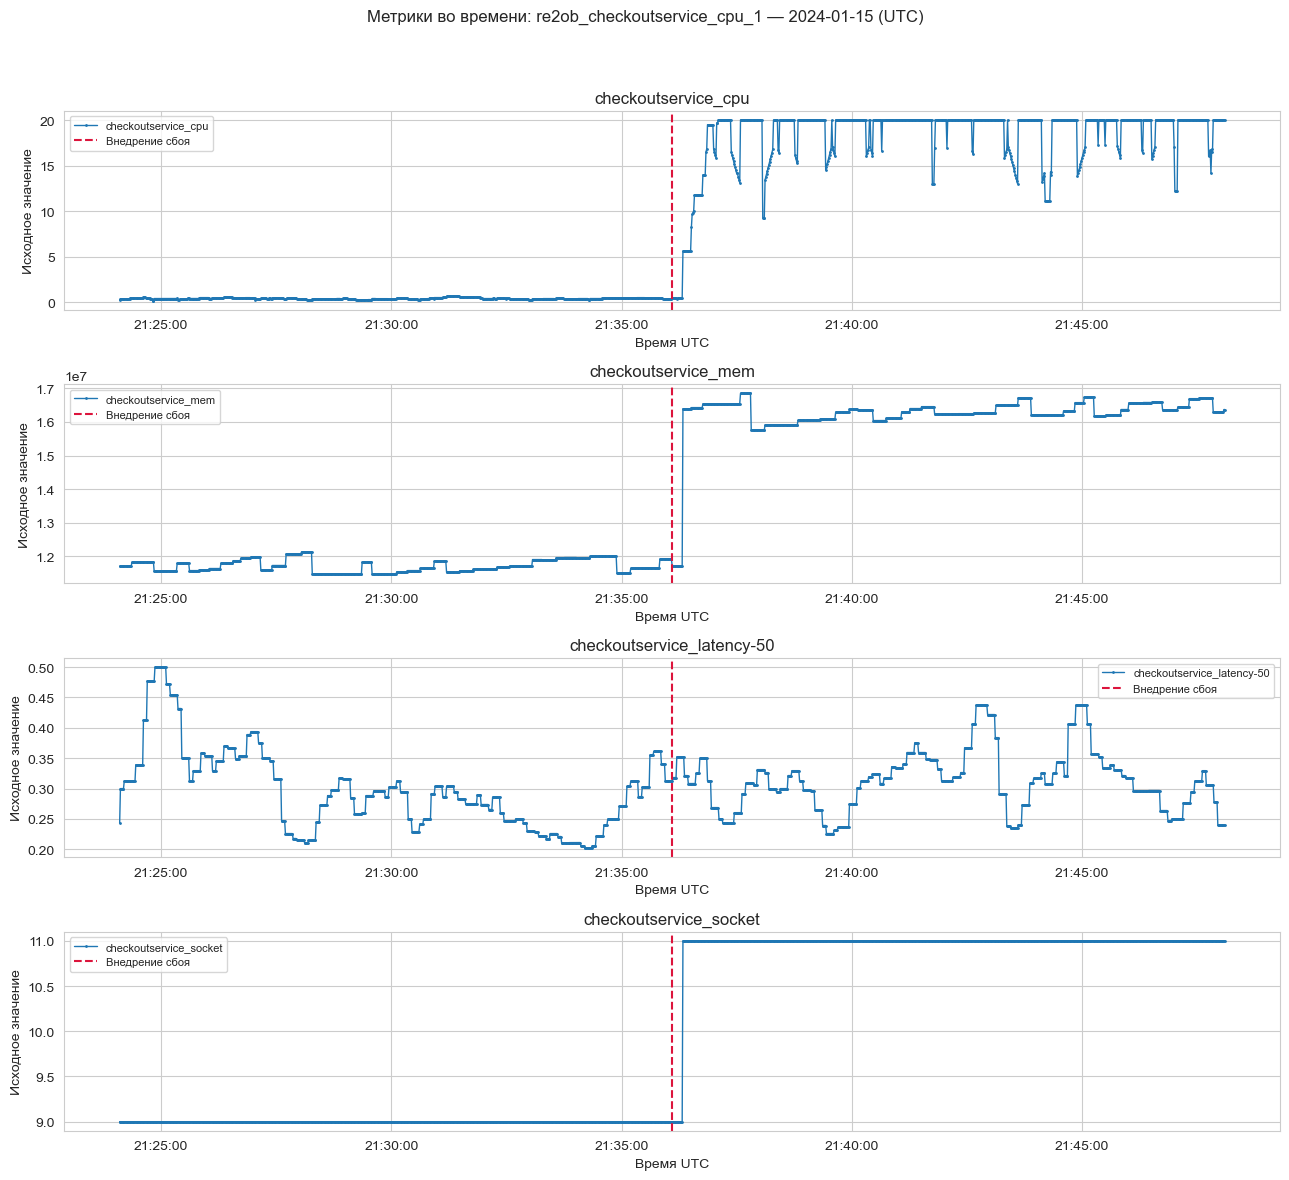

In [122]:
with sns.axes_style('whitegrid'):
    fig, axes = plt.subplots(len(selected), 1, figsize=(13, 3 * len(selected)), squeeze=False)
    for ax, c in zip(axes.flat, selected):
        plot = pd.DataFrame({'Время': timestamps, c: finite[c]}).dropna(subset=['Время']).sort_values('Время')
        ax.plot(plot['Время'], plot[c], linewidth=1, marker=".", markersize=2, label=c)
        ax.axvline(inject_time, color='crimson', linestyle='--', label='Внедрение сбоя')
        ax.set(title=c, xlabel='Время UTC', ylabel='Исходное значение')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S', tz=timestamps.dt.tz))
        ax.legend(fontsize=8)
    fig.suptitle(f'Метрики во времени: {case} — {timestamps.min().date()} (UTC)')
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    save_show(fig, '01_time_series.png')

Строим и сохраняем гистограммы выбранных метрик.

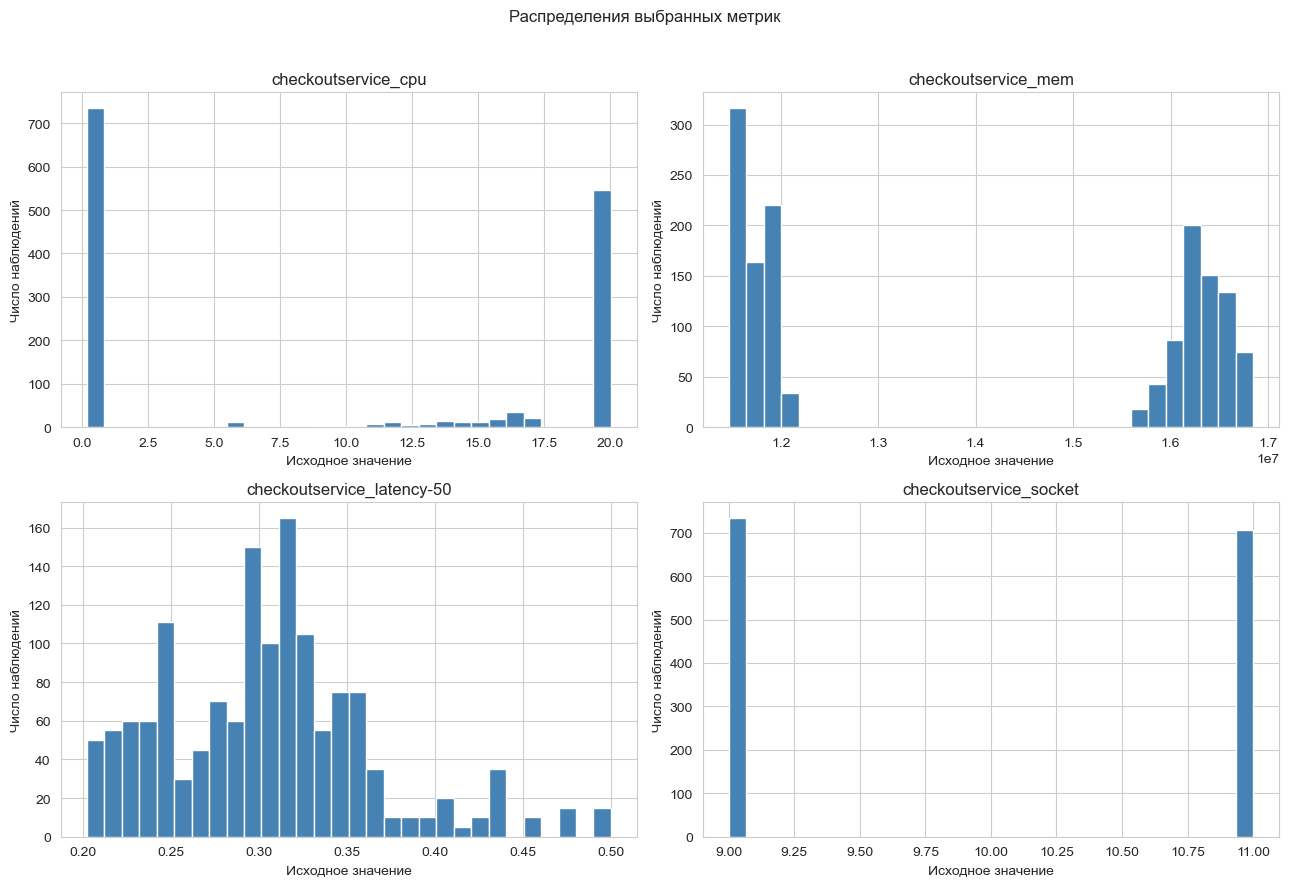

In [123]:
with sns.axes_style('whitegrid'):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, c in zip(axes.flat, selected):
        ax.hist(finite[c].dropna(), bins=30, color='steelblue', edgecolor='white')
        ax.set(title=c, xlabel='Исходное значение', ylabel='Число наблюдений')
    for ax in list(axes.flat)[len(selected):]:
        ax.set_visible(False)
    fig.suptitle('Распределения выбранных метрик')
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    save_show(fig, '02_histograms.png')

Выбираем три пары метрик с наибольшим числом совместных наблюдений.

In [124]:
pairs = list(combinations(selected, 2))
pair_counts = {pair: len(finite[list(pair)].dropna()) for pair in pairs}
pairs = sorted(pairs, key=lambda pair: (-pair_counts[pair], pair))[:3]
if any(pair_counts[pair] < 2 for pair in pairs):
    raise ValueError('Недостаточно совместных наблюдений для трёх проекций; интерполяция не применяется.')

Строим и сохраняем три диаграммы рассеяния.

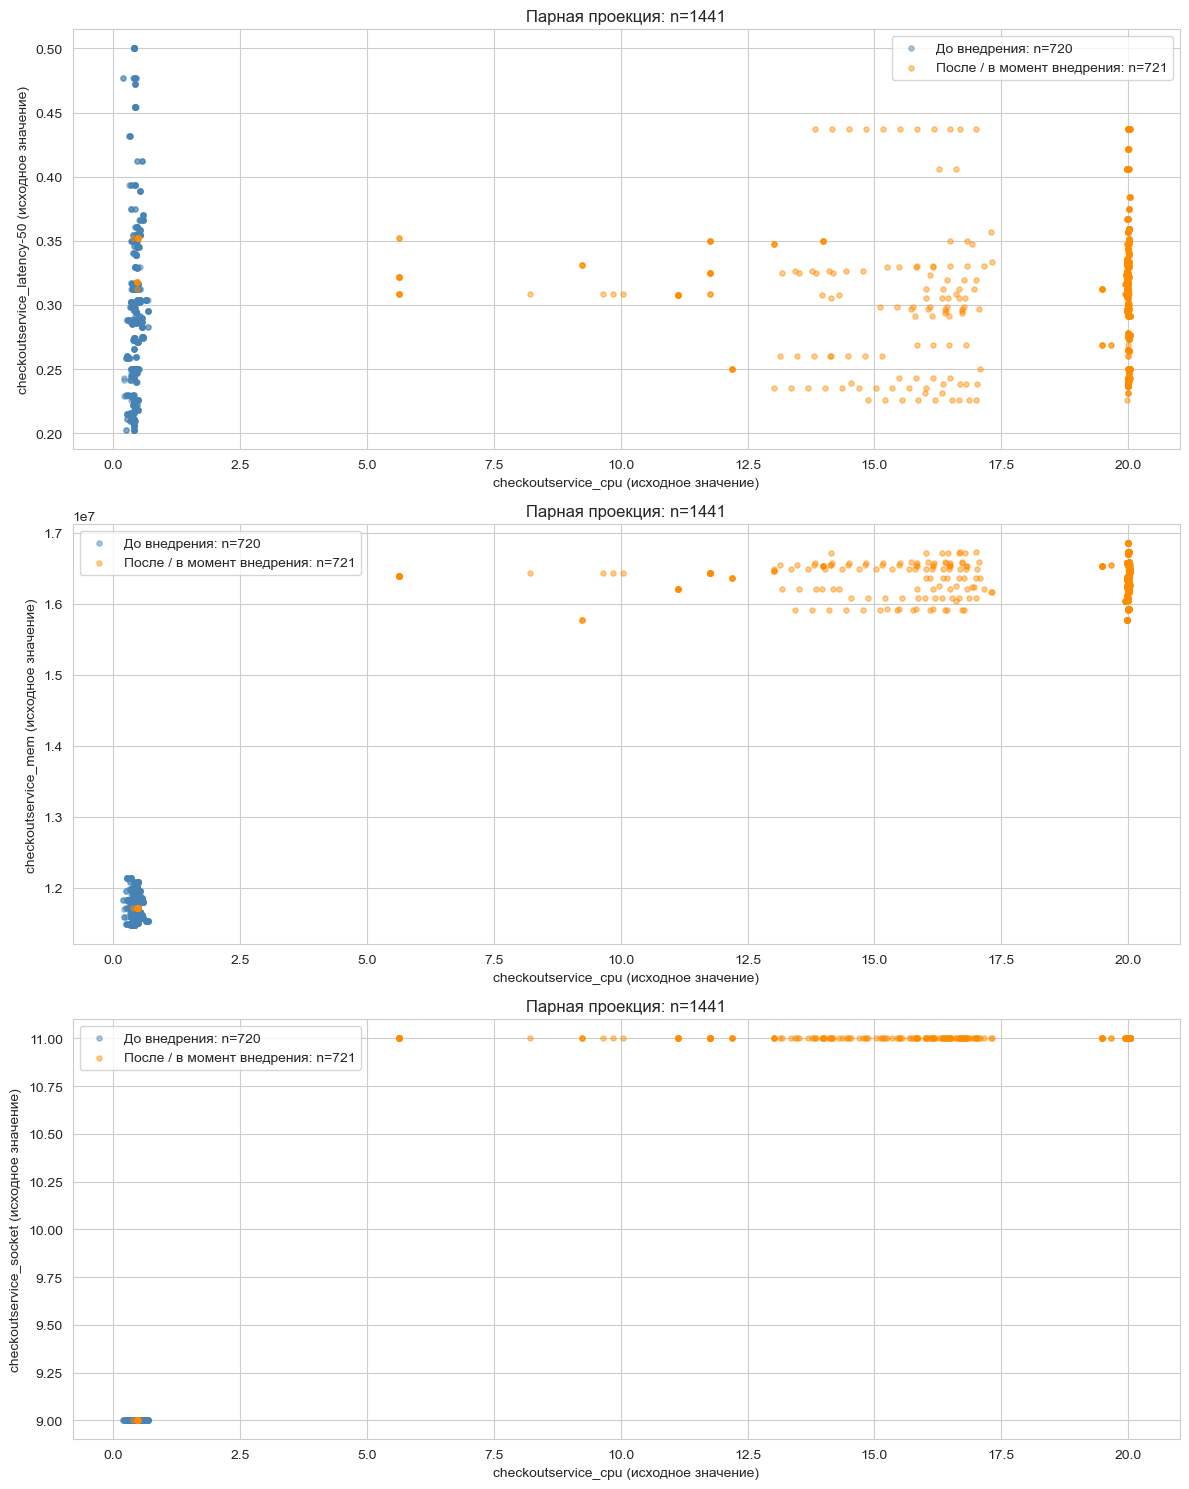

In [125]:
with sns.axes_style('whitegrid'):
    fig, axes = plt.subplots(3, 1, figsize=(12, 15))
    for ax, (x, y) in zip(axes, pairs):
        pair_data = finite[[x, y]].dropna().copy()
        for mask, label, color in [(before, 'До внедрения', 'steelblue'), (after, 'После / в момент внедрения', 'darkorange')]:
            part = pair_data.loc[pair_data.index.intersection(df.index[mask])]
            ax.scatter(part[x], part[y], s=14, alpha=0.45, label=f'{label}: n={len(part)}', color=color)
        ax.set(xlabel=x + ' (исходное значение)', ylabel=y + ' (исходное значение)',
               title=f'Парная проекция: n={len(pair_data)}')
        ax.legend()
    fig.tight_layout()
    save_show(fig, '03_scatter_pairs.png')

### 3.7. Анализ результатов
Сравниваем показатели до и после внедрения сбоя. По таблицам и графикам смотрим, какие значения изменились. Если два показателя меняются вместе, это ещё не значит, что один влияет на другой.


Сравниваем средние и медианы до и после внедрения сбоя.

In [126]:
comparison = pd.DataFrame({
    'n до': finite.loc[before, selected].count(), 'n после': finite.loc[after, selected].count(),
    'Среднее до': finite.loc[before, selected].mean(), 'Среднее после': finite.loc[after, selected].mean(),
    'Медиана до': finite.loc[before, selected].median(), 'Медиана после': finite.loc[after, selected].median()})
comparison['Разность средних'] = comparison['Среднее после'] - comparison['Среднее до']
display(comparison)
comparison.to_csv(REPORT / 'before_after.csv', index_label='Признак')

,n до,n после,Среднее до,Среднее после,Медиана до,Медиана после,Разность средних
checkoutservice_cpu,720,721,4.288544e-01,1.829024e+01,4.178548e-01,1.999256e+01,1.786138e+01
checkoutservice_mem,720,721,1.172318e+07,1.623859e+07,1.168589e+07,1.629798e+07,4.515410e+06
checkoutservice_latency-50,720,721,2.967676e-01,3.136062e-01,2.900000e-01,3.125000e-01,1.683863e-02
checkoutservice_socket,720,721,9.000000e+00,1.096117e+01,9.000000e+00,1.100000e+01,1.961165e+00


Оцениваем асимметрию распределений и возможные выбросы.

In [127]:
distribution = pd.DataFrame(index=selected)
distribution['Асимметрия'] = finite[selected].skew()
for c in selected:
    q1, q3 = finite[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    distribution.loc[c, 'За границами 1.5 IQR'] = int(((finite[c] < q1 - 1.5*iqr) | (finite[c] > q3 + 1.5*iqr)).sum())
display(distribution)

,Асимметрия,За границами 1.5 IQR
checkoutservice_cpu,0.139329,0.0
checkoutservice_mem,0.043685,0.0
checkoutservice_latency-50,0.742197,40.0
checkoutservice_socket,0.037520,0.0


Рассчитываем корреляции между выбранными метриками.

In [128]:
relations = []
for x, y in pairs:
    part = finite[[x, y]].dropna()
    r = part[x].corr(part[y]) if part[x].nunique() > 1 and part[y].nunique() > 1 else np.nan
    relations.append({'X': x, 'Y': y, 'Совместных наблюдений': len(part), 'Корреляция Пирсона': r})
relations = pd.DataFrame(relations)
display(relations)
relations.to_csv(REPORT / 'pair_relations.csv', index=False)

,X,Y,Совместных наблюдений,Корреляция Пирсона
0,checkoutservice_cpu,checkoutservice_latency-50,1441,0.133430
1,checkoutservice_cpu,checkoutservice_mem,1441,0.971621
2,checkoutservice_cpu,checkoutservice_socket,1441,0.976252


Формируем и сохраняем текст анализа результатов.

In [129]:
lines = [
    f'Мы изучили пример сбоя **{case}**. В таблице **{len(df)}** строк: '
    f'каждая строка содержит показатели системы в один момент времени. '
    f'Всего показателей: **{len(features)}**; время записано в отдельном столбце.',
    f'Пропущенных значений в данных: **{int(df[features].isna().sum().sum())}**. '
    f'Полностью пустых показателей: **{int(df[features].isna().all().sum())}**. '
    f'Повторяющихся строк: **{duplicate_rows}**; повторяющихся временных меток: **{duplicate_times}**.',
    f'До внедрения сбоя записано **{int(before.sum())}** измерений, '
    f'начиная с момента внедрения — **{int(after.sum())}**.'
]

for c in selected:
    mean_before = comparison.loc[c, 'Среднее до']
    mean_after = comparison.loc[c, 'Среднее после']
    lines.append(f'**{c}**: среднее значение до внедрения сбоя — **{mean_before:.3f}**, '
                 f'после — **{mean_after:.3f}**.')

if case == 're2ob_checkoutservice_cpu_1':
    lines.append('На графиках видно, что после внедрения сбоя значения CPU, памяти и socket '
                 'стали выше. На гистограммах CPU и памяти есть две группы значений: '
                 'более низкие до сбоя и более высокие после него. '
                 'Задержка обработки запросов менялась и до, и после сбоя. '
                 'Её самый высокий пик был до внедрения, поэтому не каждый пик связан со сбоем.')

lines.append('Мы рассмотрели только один пример сбоя. Чтобы понять, повторяются ли такие '
             'изменения в других случаях, нужно изучить больше примеров. '
             'Единицы некоторых показателей пока не уточнены, поэтому в таблицах и графиках '
             'использованы значения из исходного файла.')
analysis_text = '\n\n'.join(lines)
display(Markdown(analysis_text))
(REPORT / 'analysis.md').write_text('# Анализ результатов\n\n' + analysis_text, encoding='utf-8')


Мы изучили пример сбоя **re2ob_checkoutservice_cpu_1**. В таблице **1441** строк: каждая строка содержит показатели системы в один момент времени. Всего показателей: **72**; время записано в отдельном столбце.

Пропущенных значений в данных: **4**. Полностью пустых показателей: **0**. Повторяющихся строк: **0**; повторяющихся временных меток: **0**.

До внедрения сбоя записано **720** измерений, начиная с момента внедрения — **721**.

**checkoutservice_cpu**: среднее значение до внедрения сбоя — **0.429**, после — **18.290**.

**checkoutservice_mem**: среднее значение до внедрения сбоя — **11723184.356**, после — **16238594.840**.

**checkoutservice_latency-50**: среднее значение до внедрения сбоя — **0.297**, после — **0.314**.

**checkoutservice_socket**: среднее значение до внедрения сбоя — **9.000**, после — **10.961**.

На графиках видно, что после внедрения сбоя значения CPU, памяти и socket стали выше. На гистограммах CPU и памяти есть две группы значений: более низкие до сбоя и более высокие после него. Задержка обработки запросов менялась и до, и после сбоя. Её самый высокий пик был до внедрения, поэтому не каждый пик связан со сбоем.

Мы рассмотрели только один пример сбоя. Чтобы понять, повторяются ли такие изменения в других случаях, нужно изучить больше примеров. Единицы некоторых показателей пока не уточнены, поэтому в таблицах и графиках использованы значения из исходного файла.

1438

## 4. Заключение
В этой работе были приобретены навыки загрузки данных, просматра таблиц, находить пропуски, считать средние значения и строить графики. Ниже приведены основные результаты.


Выводим итоговые результаты лабораторной работы.

In [130]:
display(Markdown(
    f'Мы загрузили данные примера сбоя **{case}**: **{len(df)}** строк. Количество показателей: **{len(features)}**. '
    f'Количество пропущенных значений: **{int(df[features].isna().sum().sum())}**. '
    f'Выбрали несколько показателей (**{len(selected)}**) и построили графики, чтобы сравнить значения до и после внедрения сбоя. '
    'Графики помогли заметить изменения в работе системы. '
    'В следующих работах эти данные можно использовать, чтобы учиться находить сбои. '
    'В этой работе модели машинного обучения не создавались.'))

display(Markdown(
    f'В учебном примере Iris мы изучили данные о **{len(iris)}** цветках трёх видов. '
    f'Для каждого цветка записаны длина и ширина чашелистика и лепестка. '
    f'Мы построили **{len(iris_pairs)}** графиков с разными парами размеров '
    'и увидели, чем отличаются группы цветов.'))


Мы загрузили данные примера сбоя **re2ob_checkoutservice_cpu_1**: **1441** строк. Количество показателей: **72**. Количество пропущенных значений: **4**. Выбрали несколько показателей (**4**) и построили графики, чтобы сравнить значения до и после внедрения сбоя. Графики помогли заметить изменения в работе системы. В следующих работах эти данные можно использовать, чтобы учиться находить сбои. В этой работе модели машинного обучения не создавались.

В учебном примере Iris мы изучили данные о **150** цветках трёх видов. Для каждого цветка записаны длина и ширина чашелистика и лепестка. Мы построили **6** графиков с разными парами размеров и увидели, чем отличаются группы цветов.